In [1]:
import numpy,pandas,json,scipy
from matplotlib import pyplot
import matplotlib.patches as patches

from geochemistry_helpers import Sampling,GaussianProcess

# Set default dpi for saving
pyplot.rcParams['savefig.dpi'] = 600
# pyplot.rcParams.update({
#     "figure.facecolor":  (0.0, 0.0, 0.0, 0.0),
#     "axes.facecolor":    (0.0, 0.0, 0.0, 0.0),
#     "savefig.facecolor": (0.0, 0.0, 0.0, 0.0),
# })

In [2]:
# Cadmium calcium data
cadmium_calcium_ancora_acarinina = pandas.read_excel("./data/input/cadmium_calcium.xlsx",sheet_name="Ancora",usecols="A,D,E",header=2,names=["Species","Age","Cd/Ca"]).dropna(subset=["Cd/Ca"])
cadmium_calcium_ancora_subbotina = pandas.read_excel("./data/input/cadmium_calcium.xlsx",sheet_name="Ancora",usecols="G,J,K",header=2,names=["Species","Age","Cd/Ca"]).dropna(subset=["Cd/Ca"])

cadmium_calcium_southdover_acarinina = pandas.read_excel("./data/input/cadmium_calcium.xlsx",sheet_name="South Dover Bridge",usecols="A,D,E",header=2,names=["Species","Age","Cd/Ca"]).dropna(subset=["Cd/Ca"])
cadmium_calcium_southdover_subbotina = pandas.read_excel("./data/input/cadmium_calcium.xlsx",sheet_name="South Dover Bridge",usecols="G,J,K",header=2,names=["Species","Age","Cd/Ca"]).dropna(subset=["Cd/Ca"])
cadmium_calcium_southdover_morozovella = pandas.read_excel("./data/input/cadmium_calcium.xlsx",sheet_name="South Dover Bridge",usecols="M,P,Q",header=2,names=["Species","Age","Cd/Ca"]).dropna(subset=["Cd/Ca"])
cadmium_calcium_southdover_acutus = pandas.read_excel("./data/input/cadmium_calcium.xlsx",sheet_name="South Dover Bridge",usecols="S,V,W",header=2,names=["Species","Age","Cd/Ca"]).dropna(subset=["Cd/Ca"])

cadmium_calcium_data = pandas.concat([cadmium_calcium_ancora_acarinina,
                                                        cadmium_calcium_ancora_subbotina,
                                                        cadmium_calcium_southdover_acarinina,
                                                        cadmium_calcium_southdover_subbotina,
                                                        cadmium_calcium_southdover_morozovella,
                                                        cadmium_calcium_southdover_acutus],ignore_index=True)


In [3]:
# Load in data
## Data
svalbard_data = pandas.read_excel("./data/input/cadmium_data.xlsx",usecols="A:I").dropna(subset=["δ114Cd(‰)"])
arctic_data = pandas.read_excel("./data/input/cadmium_data.xlsx",usecols="K:S").dropna(subset=["δ114Cd(‰).1"])
northsea_data = pandas.read_excel("./data/input/cadmium_data.xlsx",usecols="U:AC").dropna(subset=["δ114Cd(‰).2"])
kheu_data = pandas.read_excel("./data/input/cadmium_data.xlsx",usecols="AI:AQ").dropna(subset=["δ114Cd(‰).3"])

svalbard_data["2se"] = svalbard_data["2se"]
arctic_data["2se.1"] = arctic_data["2se.1"]
northsea_data["2se.2"] = northsea_data["2se.2"]
kheu_data["2se.4"] = kheu_data["2se.4"]

# Load in GP
cadmium_gp = GaussianProcess().fromJSON("./data/output/cadmium_gp.json")


# Load in prior_results
with open("./data/output/invert_organic_prior_results.json","r") as file:
    prior_results = json.load(file)

# Load in posterior_results
with open("./data/output/invert_organic_posterior_results.json","r") as file:
    posterior_results = json.load(file)

# Load in metrics
prior_metrics = pandas.read_excel("./data/output/invert_organic_prior_metrics.xlsx")
posterior_metrics = pandas.read_excel("./data/output/invert_organic_posterior_metrics.xlsx")

timestep = prior_metrics["time"].values[0]-prior_metrics["time"].values[1]

<>:23: SyntaxWarning: invalid escape sequence '\d'
<>:23: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_841/617299309.py:23: SyntaxWarning: invalid escape sequence '\d'
  axes[0].set_ylabel("$\delta^{114}$Cd (‰)")


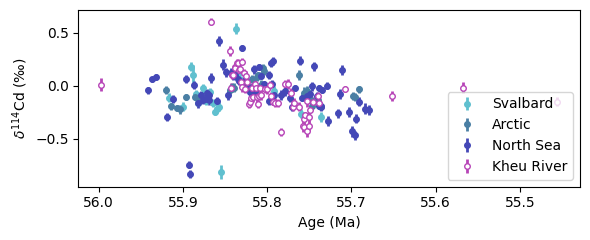

In [4]:
# Plot Data
figure,axis = pyplot.subplots(nrows=1,sharex=True,figsize=(6,2.5))
axes = [axis]

common_attributes = {"fmt":'o',
                     "zorder":0,
                     "markersize":4,
                     "linewidth":2}
# handle_0 = axes[0].errorbar(svalbard_data["Age model"],svalbard_data["δ114Cd(‰)"],yerr=svalbard_data["2se"]/2*10,fmt='o',color="#60c0cf",zorder=-1,markersize=5,alpha=0.5,linewidth=2)
handle_0 = axes[0].errorbar(svalbard_data["Age model"],svalbard_data["δ114Cd(‰)"],yerr=svalbard_data["2se"],color="#60c0cf",ecolor="#60c0cf",**common_attributes)

# handle_1 = axes[0].errorbar(arctic_data["Age model.1"],arctic_data["δ114Cd(‰).1"],yerr=arctic_data["2se.1"]/2*10,fmt='o',color="#4a7fa4",zorder=-1,markersize=5,alpha=0.5,linewidth=2)
handle_1 = axes[0].errorbar(arctic_data["Age model.1"],arctic_data["δ114Cd(‰).1"],yerr=arctic_data["2se.1"],color="#4a7fa4",ecolor="#4a7fa4",**common_attributes)

# handle_2 = axes[0].errorbar(northsea_data["Age model.2"],northsea_data["δ114Cd(‰).2"],yerr=northsea_data["2se.2"]/2*10,fmt='o',color="#4448b7",zorder=-1,markersize=5,alpha=0.5,linewidth=2)
handle_2 = axes[0].errorbar(northsea_data["Age model.2"],northsea_data["δ114Cd(‰).2"],yerr=northsea_data["2se.2"],color="#4448b7",ecolor="#4448b7",**common_attributes)

# handle_3 = axes[0].errorbar(kheu_data["Age model.3"],kheu_data["δ114Cd(‰).3"],yerr=kheu_data["2se.4"]/2*10,fmt='o',color="#b744b7",zorder=-1,markersize=5,alpha=0.5,linewidth=2)
handle_3 = axes[0].errorbar(kheu_data["Age model.3"],kheu_data["δ114Cd(‰).3"],yerr=kheu_data["2se.4"],markeredgecolor="#b744b7",ecolor="#b744b7",fmt='o',markerfacecolor="#ffffff",zorder=0,markersize=4,linewidth=2)

axes[0].legend([handle_0,handle_1,handle_2,handle_3],["Svalbard","Arctic","North Sea","Kheu River"])

axes[0].set_ylabel("$\delta^{114}$Cd (‰)")
axes[0].set_xlabel("Age (Ma)")

axes[0].invert_xaxis()

figure.tight_layout()
figure.savefig("./figures/cadmium_data.png",transparent=True)


<>:9: SyntaxWarning: invalid escape sequence '\d'
<>:9: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_841/612256120.py:9: SyntaxWarning: invalid escape sequence '\d'
  axes[0].set_ylabel("$\delta^{114}$Cd (‰)")


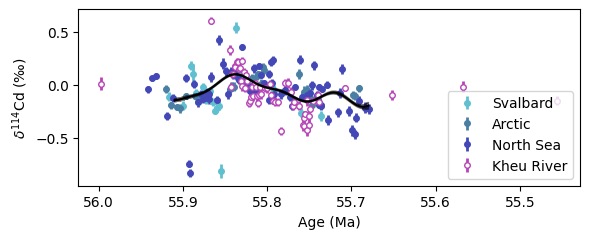

In [5]:
# Plot
figure

cadmium_gp.plotMean(group=-1,color="black",axis=axes[0])
cadmium_gp.plotArea(group=-1,color="black",alpha=0.5,set_axes=False,axis=axes[0])

# axes[0].legend([handle_0,handle_1,handle_2],["Svalbard","Arctic","North Sea"])

axes[0].set_ylabel("$\delta^{114}$Cd (‰)")
axes[0].set_xlabel("Age (Ma)")

# axes[0].invert_xaxis()

figure.tight_layout()
figure.savefig("./figures/cadmium_data_gp.png",transparent=True)


figure

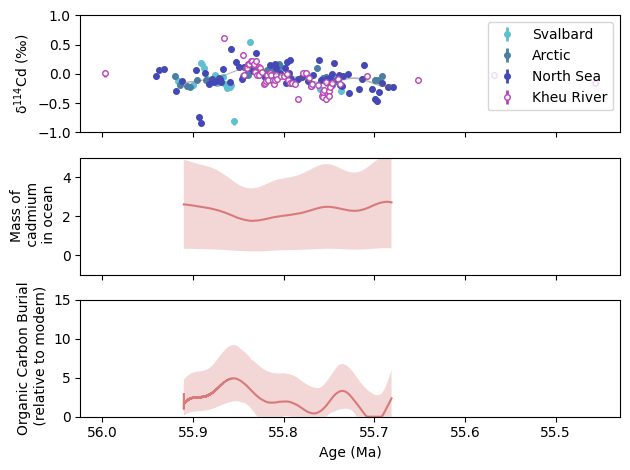

In [6]:
# Plot
figure,axes = pyplot.subplots(nrows=3,sharex=True)

common_attributes = {"fmt":'o',
                     "zorder":0,
                     "markersize":4,
                     "linewidth":2}
# handle_0 = axes[0].errorbar(svalbard_data["Age model"],svalbard_data["δ114Cd(‰)"],yerr=svalbard_data["2se"]/2*10,fmt='o',color="#60c0cf",zorder=-1,markersize=5,alpha=0.5,linewidth=2)
handle_0 = axes[0].errorbar(svalbard_data["Age model"],svalbard_data["δ114Cd(‰)"],yerr=svalbard_data["2se"],color="#60c0cf",ecolor="#60c0cf",**common_attributes)

# handle_1 = axes[0].errorbar(arctic_data["Age model.1"],arctic_data["δ114Cd(‰).1"],yerr=arctic_data["2se.1"]/2*10,fmt='o',color="#4a7fa4",zorder=-1,markersize=5,alpha=0.5,linewidth=2)
handle_1 = axes[0].errorbar(arctic_data["Age model.1"],arctic_data["δ114Cd(‰).1"],yerr=arctic_data["2se.1"],color="#4a7fa4",ecolor="#4a7fa4",**common_attributes)

# handle_2 = axes[0].errorbar(northsea_data["Age model.2"],northsea_data["δ114Cd(‰).2"],yerr=northsea_data["2se.2"]/2*10,fmt='o',color="#4448b7",zorder=-1,markersize=5,alpha=0.5,linewidth=2)
handle_2 = axes[0].errorbar(northsea_data["Age model.2"],northsea_data["δ114Cd(‰).2"],yerr=northsea_data["2se.2"],color="#4448b7",ecolor="#4448b7",**common_attributes)

# handle_3 = axes[0].errorbar(kheu_data["Age model.3"],kheu_data["δ114Cd(‰).3"],yerr=kheu_data["2se.4"]/2*10,fmt='o',color="#b744b7",zorder=-1,markersize=5,alpha=0.5,linewidth=2)
handle_3 = axes[0].errorbar(kheu_data["Age model.3"],kheu_data["δ114Cd(‰).3"],yerr=kheu_data["2se.4"],markeredgecolor="#b744b7",ecolor="#b744b7",fmt='o',markerfacecolor="#ffffff",zorder=0,markersize=4,linewidth=2)

axes[0].legend([handle_0,handle_1,handle_2,handle_3],["Svalbard","Arctic","North Sea","Kheu River"])

# cadmium_gp.plotArea(axis=axes[0],group=-1,color="#aaaaaa",alpha=0.5,set_axes=False,zorder=1)
# cadmium_gp.plotMean(axis=axes[0],group=-1,color="#666666",linestyle="--",zorder=2)

indices = range(0,len(prior_results))
colormap = pyplot.colormaps.get_cmap("autumn")(numpy.linspace(0,1,len(indices)))


ages = numpy.concatenate((svalbard_data["Age model"],arctic_data["Age model.1"],northsea_data["Age model.2"]))
time = prior_results[0]["time"][:-1]
interpolation_ages = [ages,time]

# First subplot
d114Cd_prior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1]))) 
d114Cd_prior_patch_y = numpy.concatenate((numpy.array(prior_metrics["seawater_d114Cd_lower_quantile"]),
                                    numpy.array(prior_metrics["seawater_d114Cd_upper_quantile"][::-1])))

d114Cd_prior_patch = patches.Polygon(numpy.concatenate((d114Cd_prior_patch_x[:,numpy.newaxis],d114Cd_prior_patch_y[:,numpy.newaxis]),axis=1),facecolor="#666666",alpha=0.5)
axes[0].add_patch(d114Cd_prior_patch)



axes[0].set_ylim((-1.0,1.0))
axes[0].set_ylabel("δ$^{114}$Cd (‰)")


# Second subplot
seawater_prior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1])))
seawater_prior_patch_y = numpy.concatenate((numpy.array(prior_metrics["seawater_mass_lower_quantile"]/8.36e11),
                                    numpy.array(prior_metrics["seawater_mass_upper_quantile"][::-1]/8.36e11)))

seawater_prior_patch = patches.Polygon(numpy.concatenate((seawater_prior_patch_x[:,numpy.newaxis],seawater_prior_patch_y[:,numpy.newaxis]),axis=1),facecolor="#d97979",alpha=0.3)
axes[1].add_patch(seawater_prior_patch)

axes[1].plot(time,prior_metrics["seawater_mass_median"]/8.36e11,color="#d97979",linestyle="-")

axes[1].set_ylabel("Mass of\n cadmium\n in ocean")
axes[1].set_ylim((-1.0,5.0))


# Third subplot
organic_prior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1]))) 
organic_prior_patch_y = numpy.concatenate((numpy.array(prior_metrics["organic_flux_lower_quantile"]/5287500),
                                    numpy.array(prior_metrics["organic_flux_upper_quantile"][::-1]/5287500)))

organic_prior_patch = patches.Polygon(numpy.concatenate((organic_prior_patch_x[:,numpy.newaxis],
                                                                    organic_prior_patch_y[:,numpy.newaxis]),
                                                                    axis=1),
                                                         facecolor="#d97979",
                                                         alpha=0.3)
axes[2].add_patch(organic_prior_patch)
axes[2].plot(time,prior_metrics["organic_flux_median"]/5287500,color="#d97979",linestyle="-")


axes[2].set_ylim((0.0,15.0))

axes[2].invert_xaxis()
axes[2].set_xlabel("Age (Ma)")
axes[2].set_ylabel("Organic Carbon Burial\n (relative to modern)")

figure.tight_layout()
figure.savefig("./figures/cadmium_prior.png",transparent=True)

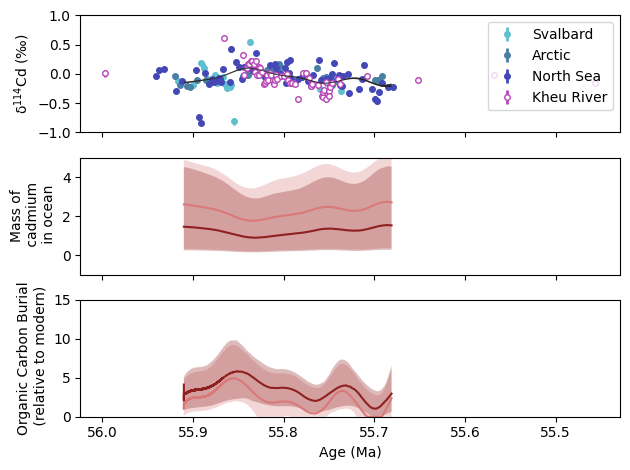

In [7]:
d114Cd_posterior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1])))
d114Cd_posterior_patch_y = numpy.concatenate((numpy.array(posterior_metrics["seawater_d114Cd_lower_quantile"]),
                                    numpy.array(posterior_metrics["seawater_d114Cd_upper_quantile"][::-1])))
d114Cd_posterior_patch = patches.Polygon(numpy.concatenate((d114Cd_posterior_patch_x[:,numpy.newaxis],d114Cd_posterior_patch_y[:,numpy.newaxis]),axis=1),facecolor="#272727",alpha=1.0)
axes[0].add_patch(d114Cd_posterior_patch)


seawater_posterior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1])))
seawater_posterior_patch_y = numpy.concatenate((numpy.array(posterior_metrics["seawater_mass_lower_quantile"]/8.36e11),
                                        numpy.array(posterior_metrics["seawater_mass_upper_quantile"][::-1]/8.36e11)))

seawater_posterior_patch = patches.Polygon(numpy.concatenate((seawater_posterior_patch_x[:,numpy.newaxis],seawater_posterior_patch_y[:,numpy.newaxis]),axis=1),facecolor="#8f2020",alpha=0.3)
axes[1].add_patch(seawater_posterior_patch)
axes[1].plot(time,posterior_metrics["seawater_mass_median"]/8.36e11,color="#8f2020",linestyle="-")


organic_posterior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1])))
organic_posterior_patch_y = numpy.concatenate((numpy.array(posterior_metrics["organic_flux_lower_quantile"]/5287500),
                                    numpy.array(posterior_metrics["organic_flux_upper_quantile"][::-1]/5287500)))

organic_posterior_patch = patches.Polygon(numpy.concatenate((organic_posterior_patch_x[:,numpy.newaxis],
                                                                        organic_posterior_patch_y[:,numpy.newaxis]),
                                                                        axis=1),
                                                                facecolor="#8f2020",
                                                                alpha=0.3)
axes[2].add_patch(organic_posterior_patch)
axes[2].plot(time,posterior_metrics["organic_flux_median"]/5287500,color="#8f2020",linestyle="-")

figure.savefig("./figures/cadmium_posterior.png",transparent=True)
figure




Text(0, 0.5, 'Organic Carbon Burial\n (relative to modern)')

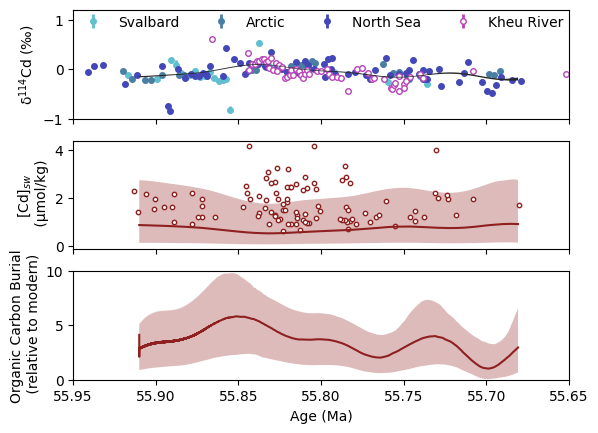

In [8]:
# Plot
figure,axes = pyplot.subplots(nrows=3,sharex=True)

common_attributes = {"fmt":'o',
                     "zorder":0,
                     "markersize":4,
                     "linewidth":2}
handle_0 = axes[0].errorbar(svalbard_data["Age model"],svalbard_data["δ114Cd(‰)"],yerr=svalbard_data["2se"],color="#60c0cf",ecolor="#60c0cf",**common_attributes)
handle_1 = axes[0].errorbar(arctic_data["Age model.1"],arctic_data["δ114Cd(‰).1"],yerr=arctic_data["2se.1"],color="#4a7fa4",ecolor="#4a7fa4",**common_attributes)
handle_2 = axes[0].errorbar(northsea_data["Age model.2"],northsea_data["δ114Cd(‰).2"],yerr=northsea_data["2se.2"],color="#4448b7",ecolor="#4448b7",**common_attributes)
handle_3 = axes[0].errorbar(kheu_data["Age model.3"],kheu_data["δ114Cd(‰).3"],yerr=kheu_data["2se.4"],markeredgecolor="#b744b7",ecolor="#b744b7",fmt='o',markerfacecolor="#ffffff",zorder=0,markersize=4,linewidth=2)

axes[0].legend([handle_0,handle_1,handle_2,handle_3],["Svalbard","Arctic","North Sea","Kheu River"],ncols=4,loc="upper center",bbox_to_anchor=(0,0.07,1,1),frameon=False)

indices = range(0,len(prior_results))
colormap = pyplot.colormaps.get_cmap("autumn")(numpy.linspace(0,1,len(indices)))


ages = numpy.concatenate((svalbard_data["Age model"],arctic_data["Age model.1"],northsea_data["Age model.2"]))
time = prior_results[0]["time"][0:-1]
interpolation_ages = [ages,time]

# First subplot
d114Cd_posterior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1])))
d114Cd_posterior_patch_y = numpy.concatenate((numpy.array(posterior_metrics["seawater_d114Cd_lower_quantile"][0:]),
                                    numpy.array(posterior_metrics["seawater_d114Cd_upper_quantile"][0:][::-1])))
d114Cd_posterior_patch = patches.Polygon(numpy.concatenate((d114Cd_posterior_patch_x[:,numpy.newaxis],d114Cd_posterior_patch_y[:,numpy.newaxis]),axis=1),facecolor="#272727",alpha=1.0)
axes[0].add_patch(d114Cd_posterior_patch)

axes[0].set_ylim((-1.0,1.2))
axes[0].set_ylabel("δ$^{114}$Cd (‰)")


# Second subplot
seawater_posterior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1])))
seawater_posterior_patch_y = numpy.concatenate((numpy.array(1e6*posterior_metrics["seawater_mass_lower_quantile"][0:]/1.37e18),
                                        numpy.array(1e6*posterior_metrics["seawater_mass_upper_quantile"][0:][::-1]/1.37e18)))

seawater_posterior_patch = patches.Polygon(numpy.concatenate((seawater_posterior_patch_x[:,numpy.newaxis],seawater_posterior_patch_y[:,numpy.newaxis]),axis=1),facecolor="#8f2020",alpha=0.3)
axes[1].add_patch(seawater_posterior_patch)
axes[1].plot(time,1e6*posterior_metrics["seawater_mass_median"][0:]/1.37e18,color="#8f2020",linestyle="-")

axes[1].set_ylabel("[Cd]$_{sw}$\n (μmol/kg)")
# axes[1].set_ylim((-0.0,5.0))

axes[1].scatter(cadmium_calcium_data["Age"],cadmium_calcium_data["Cd/Ca"]*17,color="#ffffff",edgecolor="#8f2020",s=10,zorder=1)

# Third subplot
organic_posterior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1])))
organic_posterior_patch_y = numpy.concatenate((numpy.array(posterior_metrics["organic_flux_lower_quantile"][0:]/5287500),
                                    numpy.array(posterior_metrics["organic_flux_upper_quantile"][0:][::-1]/5287500)))

organic_posterior_patch = patches.Polygon(numpy.concatenate((organic_posterior_patch_x[:,numpy.newaxis],
                                                                        organic_posterior_patch_y[:,numpy.newaxis]),
                                                                        axis=1),
                                                                facecolor="#8f2020",
                                                                alpha=0.3)
axes[2].add_patch(organic_posterior_patch)
axes[2].plot(time,posterior_metrics["organic_flux_median"][0:]/5287500,color="#8f2020",linestyle="-")


axes[2].set_xlim((55.65,55.95))
axes[2].set_ylim((0.0,10.0))

axes[2].invert_xaxis()
axes[2].set_xlabel("Age (Ma)")
axes[2].set_ylabel("Organic Carbon Burial\n (relative to modern)")

# figure.tight_layout()
# figure.savefig("./figures/cadmium_prior.png",transparent=True)


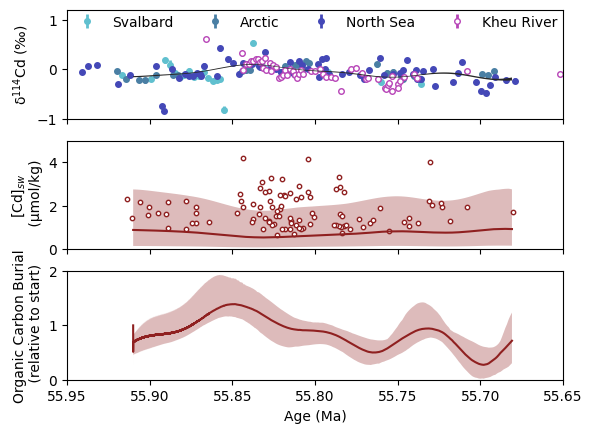

In [9]:
axes[2].clear()

axes[0].set_xlim((55.95,55.65))
axes[1].set_ylim((0.0,5.0))

# Third subplot
organic_prior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1]))) 
organic_prior_patch_y = numpy.concatenate((numpy.array(posterior_metrics["relative_organic_flux_lower_quantile"][0:]),
                                    numpy.array(posterior_metrics["relative_organic_flux_upper_quantile"][0:][::-1])))

organic_prior_patch = patches.Polygon(numpy.concatenate((organic_prior_patch_x[:,numpy.newaxis],
                                                                    organic_prior_patch_y[:,numpy.newaxis]),
                                                                    axis=1),
                                                         facecolor="#8f2020",
                                                         alpha=0.3)
axes[2].add_patch(organic_prior_patch)
axes[2].plot(time,posterior_metrics["relative_organic_flux_median"][0:],color="#8f2020",linestyle="-")

axes[2].set_ylim((0.0,2.0))
axes[2].set_ylabel("Organic Carbon Burial\n (relative to start)")
axes[2].set_xlabel("Age (Ma)")

figure.savefig("./figures/cadmium_posterior_relative.png",transparent=True,dpi=600)

figure


Text(0, 0.5, 'Organic Carbon Burial\n (relative to initial)')

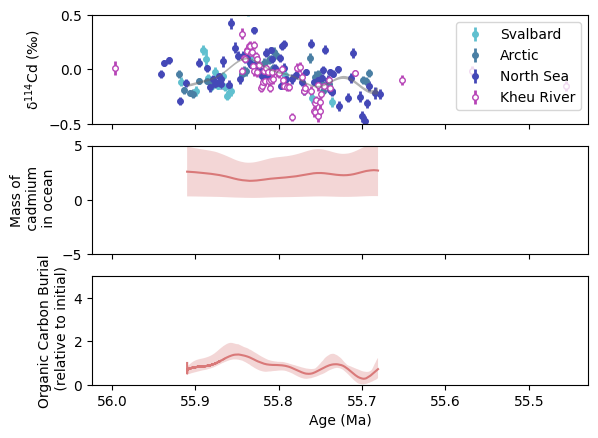

In [10]:
# Plot
figure,axes = pyplot.subplots(nrows=3,sharex=True)
common_attributes = {"fmt":'o',
                     "zorder":0,
                     "markersize":4,
                     "linewidth":2}
# handle_0 = axes[0].errorbar(svalbard_data["Age model"],svalbard_data["δ114Cd(‰)"],yerr=svalbard_data["2se"]/2*10,fmt='o',color="#60c0cf",zorder=-1,markersize=5,alpha=0.5,linewidth=2)
handle_0 = axes[0].errorbar(svalbard_data["Age model"],svalbard_data["δ114Cd(‰)"],yerr=svalbard_data["2se"],color="#60c0cf",ecolor="#60c0cf",**common_attributes)

# handle_1 = axes[0].errorbar(arctic_data["Age model.1"],arctic_data["δ114Cd(‰).1"],yerr=arctic_data["2se.1"]/2*10,fmt='o',color="#4a7fa4",zorder=-1,markersize=5,alpha=0.5,linewidth=2)
handle_1 = axes[0].errorbar(arctic_data["Age model.1"],arctic_data["δ114Cd(‰).1"],yerr=arctic_data["2se.1"],color="#4a7fa4",ecolor="#4a7fa4",**common_attributes)

# handle_2 = axes[0].errorbar(northsea_data["Age model.2"],northsea_data["δ114Cd(‰).2"],yerr=northsea_data["2se.2"]/2*10,fmt='o',color="#4448b7",zorder=-1,markersize=5,alpha=0.5,linewidth=2)
handle_2 = axes[0].errorbar(northsea_data["Age model.2"],northsea_data["δ114Cd(‰).2"],yerr=northsea_data["2se.2"],color="#4448b7",ecolor="#4448b7",**common_attributes)

# handle_3 = axes[0].errorbar(kheu_data["Age model.3"],kheu_data["δ114Cd(‰).3"],yerr=kheu_data["2se.4"]/2*10,fmt='o',color="#b744b7",zorder=-1,markersize=5,alpha=0.5,linewidth=2)
handle_3 = axes[0].errorbar(kheu_data["Age model.3"],kheu_data["δ114Cd(‰).3"],yerr=kheu_data["2se.4"],markeredgecolor="#b744b7",ecolor="#b744b7",fmt='o',markerfacecolor="#ffffff",zorder=0,markersize=4,linewidth=2)

axes[0].legend([handle_0,handle_1,handle_2,handle_3],["Svalbard","Arctic","North Sea","Kheu River"])


# cadmium_gp.plotArea(axis=axes[0],group=-1,color="#aaaaaa",alpha=0.5,set_axes=False,zorder=1)
# cadmium_gp.plotMean(axis=axes[0],group=-1,color="#666666",linestyle="--",zorder=2)

indices = range(0,len(prior_results))
colormap = pyplot.colormaps.get_cmap("autumn")(numpy.linspace(0,1,len(indices)))


ages = numpy.concatenate((svalbard_data["Age model"],arctic_data["Age model.1"],northsea_data["Age model.2"]))
time = prior_results[0]["time"][:-1]
interpolation_ages = [ages,time]

# First subplot
d114Cd_prior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1]))) 
d114Cd_prior_patch_y = numpy.concatenate((numpy.array(prior_metrics["seawater_d114Cd_lower_quantile"]),
                                    numpy.array(prior_metrics["seawater_d114Cd_upper_quantile"][::-1])))

d114Cd_prior_patch = patches.Polygon(numpy.concatenate((d114Cd_prior_patch_x[:,numpy.newaxis],d114Cd_prior_patch_y[:,numpy.newaxis]),axis=1),facecolor="#666666",alpha=0.5)
axes[0].add_patch(d114Cd_prior_patch)



axes[0].set_ylim((-0.5,0.5))
axes[0].set_ylabel("δ$^{114}$Cd (‰)")


# Second subplot
seawater_prior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1])))
seawater_prior_patch_y = numpy.concatenate((numpy.array(prior_metrics["seawater_mass_lower_quantile"]/8.36e11),
                                    numpy.array(prior_metrics["seawater_mass_upper_quantile"][::-1]/8.36e11)))

seawater_prior_patch = patches.Polygon(numpy.concatenate((seawater_prior_patch_x[:,numpy.newaxis],seawater_prior_patch_y[:,numpy.newaxis]),axis=1),facecolor="#d97979",alpha=0.3)
axes[1].add_patch(seawater_prior_patch)

axes[1].plot(time,prior_metrics["seawater_mass_median"]/8.36e11,color="#d97979",linestyle="-")

axes[1].set_ylabel("Mass of\n cadmium\n in ocean")
axes[1].set_ylim((-5.0,5.0))


# Third subplot
organic_prior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1]))) 
organic_prior_patch_y = numpy.concatenate((numpy.array(posterior_metrics["relative_organic_flux_lower_quantile"]),
                                    numpy.array(posterior_metrics["relative_organic_flux_upper_quantile"][::-1])))

organic_prior_patch = patches.Polygon(numpy.concatenate((organic_prior_patch_x[:,numpy.newaxis],
                                                                    organic_prior_patch_y[:,numpy.newaxis]),
                                                                    axis=1),
                                                         facecolor="#d97979",
                                                         alpha=0.3)
axes[2].add_patch(organic_prior_patch)
axes[2].plot(time,posterior_metrics["relative_organic_flux_median"],color="#d97979",linestyle="-")


axes[2].set_ylim((0.0,5.0))

axes[2].invert_xaxis()
axes[2].set_xlabel("Age (Ma)")
axes[2].set_ylabel("Organic Carbon Burial\n (relative to initial)")


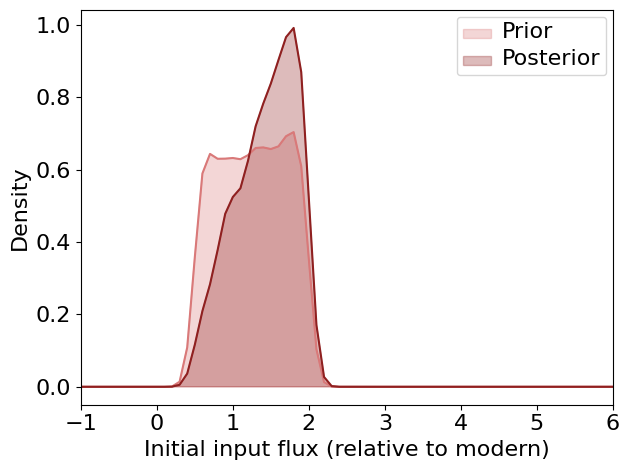

In [11]:
prior_initial_input_fluxes = numpy.array([model["input_mass"][0]/30000000.0 for model in prior_results])
posterior_initial_input_fluxes = numpy.array([model["input_mass"][0]/30000000.0 for model in posterior_results])

figure = pyplot.figure()
axes = figure.add_subplot(111)

kde_x = numpy.arange(-10,10,0.1)
prior_kde = scipy.stats.gaussian_kde(prior_initial_input_fluxes)
posterior_kde = scipy.stats.gaussian_kde(posterior_initial_input_fluxes)

axes.plot(kde_x,prior_kde(kde_x),color="#d97979")
axes.plot(kde_x,posterior_kde(kde_x),color="#8f2020")

handle_0 = axes.fill_between(kde_x,prior_kde(kde_x),color="#d97979",alpha=0.3)
handle_1 = axes.fill_between(kde_x,posterior_kde(kde_x),color="#8f2020",alpha=0.3)

axes.set_xlabel("Initial input flux (relative to modern)")
axes.set_ylabel("Density")

axes.set_xlim((-1.0,6.0))

# Legend
axes.legend([handle_0,handle_1],["Prior","Posterior"])

# Change the font size
for item in ([axes.title, axes.xaxis.label, axes.yaxis.label] +
             axes.get_xticklabels() + axes.get_yticklabels() + axes.get_legend().get_texts()):
    item.set_fontsize(16)


figure.tight_layout()
figure.savefig("./figures/cadmium_initial_input_flux.png",transparent=True)


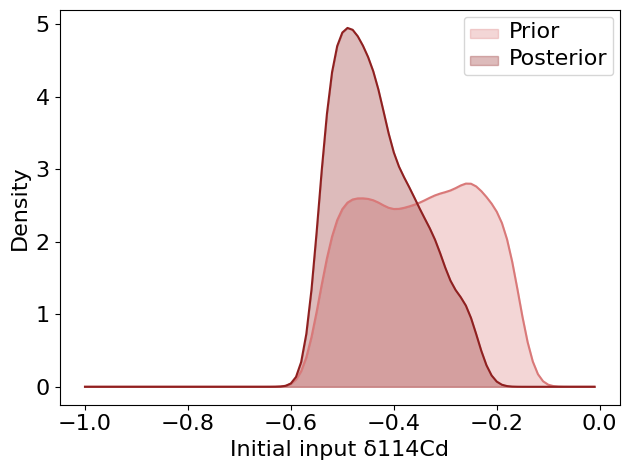

In [12]:
prior_initial_input_isotopes = numpy.array([model["input_δ114Cd"][0] for model in prior_results])
posterior_initial_input_isotopes = numpy.array([model["input_δ114Cd"][0] for model in posterior_results])

figure = pyplot.figure()
axes = figure.add_subplot(111)

kde_x = numpy.arange(-1,0,0.01)
prior_kde = scipy.stats.gaussian_kde(prior_initial_input_isotopes)
posterior_kde = scipy.stats.gaussian_kde(posterior_initial_input_isotopes)

axes.plot(kde_x,prior_kde(kde_x),color="#d97979")
axes.plot(kde_x,posterior_kde(kde_x),color="#8f2020")

handle_0 = axes.fill_between(kde_x,prior_kde(kde_x),color="#d97979",alpha=0.3)
handle_1 = axes.fill_between(kde_x,posterior_kde(kde_x),color="#8f2020",alpha=0.3)

axes.set_xlabel("Initial input δ114Cd")
axes.set_ylabel("Density")

# Legend
axes.legend([handle_0,handle_1],["Prior","Posterior"])

# Change the font size
for item in ([axes.title, axes.xaxis.label, axes.yaxis.label] +
             axes.get_xticklabels() + axes.get_yticklabels() + axes.get_legend().get_texts()):
    item.set_fontsize(16)

figure.tight_layout()
figure.savefig("./figures/cadmium_initial_input_isotopes.png",transparent=True)

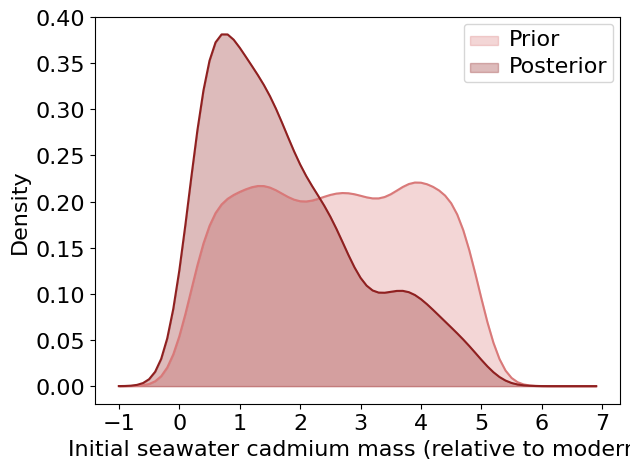

In [13]:
prior_initial_seawater_mass = numpy.array([model["seawater_mass"][0]/8.36e11 for model in prior_results])
posterior_initial_seawater_mass = numpy.array([model["seawater_mass"][0]/8.36e11 for model in posterior_results])

figure = pyplot.figure()
axes = figure.add_subplot(111)

kde_x = numpy.arange(-1,7,0.1)
prior_kde = scipy.stats.gaussian_kde(prior_initial_seawater_mass)
posterior_kde = scipy.stats.gaussian_kde(posterior_initial_seawater_mass)

axes.plot(kde_x,prior_kde(kde_x),color="#d97979")
axes.plot(kde_x,posterior_kde(kde_x),color="#8f2020")

handle_0 = axes.fill_between(kde_x,prior_kde(kde_x),color="#d97979",alpha=0.3)
handle_1 = axes.fill_between(kde_x,posterior_kde(kde_x),color="#8f2020",alpha=0.3)

axes.set_xlabel("Initial seawater cadmium mass (relative to modern)")
axes.set_ylabel("Density")

# Legend
axes.legend([handle_0,handle_1],["Prior","Posterior"])

# Change the font size
for item in ([axes.title, axes.xaxis.label, axes.yaxis.label] +
             axes.get_xticklabels() + axes.get_yticklabels() + axes.get_legend().get_texts()):
    item.set_fontsize(16)

figure.tight_layout()
figure.savefig("./figures/cadmium_initial_seawater_mass.png",transparent=True)

32000000.0
3.6958283310690976
[ 1.95695986e+00 -2.62130835e+00 -5.08003440e-01 -1.69069529e+00
 -6.57210160e-01 -1.67629742e+00 -4.54048028e+00 -1.53694305e+00
 -9.42331793e-01 -1.24788803e+00  3.45520627e-01  1.87332246e+00
 -2.75099291e+00  1.31147480e+00 -1.32552934e+00 -2.44239276e+00
 -2.45926324e+00 -8.38342765e-01 -1.98271366e+00 -2.73926105e+00
  5.53720630e+00 -6.47861352e-01  9.03706502e-01 -9.49751045e-01
 -7.08337865e-01 -2.09299416e+00 -1.74754330e+00 -3.22838393e+00
 -1.17168794e+00 -2.72573688e+00 -6.57091686e-01 -2.02862554e+00
  8.27692585e-02  1.16942103e+00  1.73895027e-01 -1.97568156e+00
 -1.04290896e+00 -3.70125805e+00 -2.64409400e+00 -3.30800300e+00
 -5.65524625e+00 -3.77710075e+00 -1.63581432e+00 -4.63930988e-01
 -2.04786511e+00 -7.04195169e-01 -1.59756760e+00 -7.10078983e-01
 -2.76732265e+00 -1.91614629e+00 -6.93236941e+00 -1.24038104e+00
 -1.45974683e+00 -1.42648938e+00 -2.10938179e+00 -3.65517692e+00
 -3.51042218e+00 -3.23435944e+00 -3.04175602e+00 -1.80862707

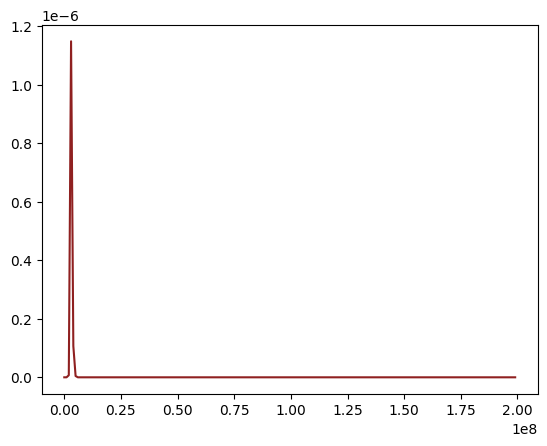

In [14]:
total_organic_fluxes = [(numpy.array(model["organic_mass"])/numpy.array(model["organic_mass"][0]))*110.0*(timestep*1e6) for model in posterior_results]
total_organic_flux = numpy.sum(total_organic_fluxes,axis=1)
extra_organic_flux = [flux-initial[0] for flux,initial in zip(total_organic_flux,total_organic_fluxes,strict=True)]

from CdBURY import CdBURY
new_extra_organic_flux = numpy.array([CdBURY.Model.integrate_excess_organic(model["organic_mass"],timestep*1e6) for model in posterior_results])

print(160*0.2e6)

figure = pyplot.figure()
axes = figure.add_subplot(111)

kde_x = numpy.arange(0,2e8,0.01e8)
posterior_kde = scipy.stats.gaussian_kde(extra_organic_flux)

# axes.plot(kde_x,prior_kde(kde_x),color="#d97979")
axes.plot(kde_x,posterior_kde(kde_x),color="#8f2020")

print(numpy.median(extra_organic_flux[0]/1e6))

print(new_extra_organic_flux/48333333333.33)